# Step 3 & 4: Model Training, Comparison & Optimization
**Goal:** Train at least 3 models, compare them using stratified cross-validation, tune the best one, and evaluate it on the unseen test set.

**Metric Choice:** Macro-Recall is our primary metric because we want to catch as many at-risk students as possible across all 3 classes (Low, Medium, High).

In [11]:
import pandas as pd
import numpy as np
import sys
sys.path.append('../src') 
from preprocessing import get_preprocessor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

# 1. Load Data
df = pd.read_csv('../data/raw/student_mental_health.csv')
X = df.drop(columns=['Mental_Health_Risk'])
y = df['Mental_Health_Risk']

# 2. Stratified 80/20 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Define Columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = [c for c in X.select_dtypes(include=['str', 'object', 'category']).columns if c != 'Student_ID']

## 1. Baseline Model Comparison
We compare 3 models using 5-Fold Cross-Validation.

In [12]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = []
for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', get_preprocessor(num_cols, cat_cols)),
        ('model', model)
    ])
    cv_results = cross_validate(pipe, X_train, y_train, cv=5, scoring=['accuracy', 'f1_macro', 'recall_macro'])
    results.append({
        "Model": name,
        "Accuracy": cv_results['test_accuracy'].mean(),
        "F1 Macro": cv_results['test_f1_macro'].mean(),
        "Recall Macro": cv_results['test_recall_macro'].mean()
    })

results_df = pd.DataFrame(results).sort_values(by='Recall Macro', ascending=False)
display(results_df)

,Model,Accuracy,F1 Macro,Recall Macro
0,Logistic Regression,0.745625,0.745225,0.745098
2,Gradient Boosting,0.693125,0.691834,0.692304
1,Random Forest,0.684375,0.681675,0.683412


## 2. Hyperparameter Optimization (GridSearchCV)
Logistic Regression won the baseline comparison. We now tune its hyperparameters (`C` and `solver`) to maximize Macro-Recall.

In [14]:
from sklearn.model_selection import GridSearchCV

final_pipe = Pipeline([
    ('preprocessor', get_preprocessor(num_cols, cat_cols)),
    ('model', LogisticRegression(class_weight='balanced', random_state=42, max_iter=2000))
])

param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__solver': ['lbfgs', 'saga']
}

# CHANGED: n_jobs=-1 becomes n_jobs=1
grid_search = GridSearchCV(final_pipe, param_grid, cv=5, scoring='recall_macro', n_jobs=1)
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV Recall: {grid_search.best_score_:.4f}")

Best Parameters: {'model__C': 10, 'model__solver': 'lbfgs'}
Best CV Recall: 0.7476


## 3. Final Evaluation on Test Set
We evaluate the optimized model ONCE on the unseen test set.

--- Final Test Set Evaluation ---
              precision    recall  f1-score   support

        High       0.82      0.82      0.82       136
         Low       0.82      0.81      0.82       132
      Medium       0.63      0.64      0.64       132

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400



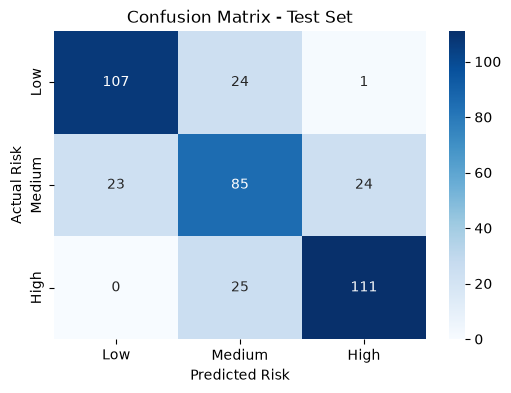

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("--- Final Test Set Evaluation ---")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6,4))
cm = confusion_matrix(y_test, y_pred, labels=['Low', 'Medium', 'High'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
plt.title('Confusion Matrix - Test Set')
plt.ylabel('Actual Risk')
plt.xlabel('Predicted Risk')
plt.show()

## 4. Save the Final Pipeline
We save the entire pipeline (preprocessor + model) to a `.joblib` file for use in the Streamlit app and Airflow.

In [16]:
import joblib
import os

os.makedirs('../models', exist_ok=True)
joblib.dump(best_model, '../models/model.joblib')
print("✅ Pipeline saved successfully to models/model.joblib")

# Verify it loads and predicts correctly
loaded_model = joblib.load('../models/model.joblib')
print(f"Sample prediction: {loaded_model.predict(X_test.iloc[:3])}")
print(f"Actual values:     {y_test.iloc[:3].values}")

✅ Pipeline saved successfully to models/model.joblib
Sample prediction: ['High' 'Medium' 'Medium']
Actual values:     <StringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str
